# vEPAC Multitask GP Surrogate Model - Step 2: Inference & Evaluation

This notebook implements the **Inference Pipeline** for the trained **Multitask Gaussian Process (`MultitaskExactGP`)** surrogate model.

It loads the saved model weights, scalers, and training points from `01_training.ipynb`, and performs:
1. Evaluation on the unseen 20% holdout test set (264 samples), reporting MAE, RMSE, R² Score, Interval ECE, and Parity Plots.
2. Generalization evaluation on the unseen 5th Set (`test_selected_data.csv`, 594 samples), generating predictions and out-of-sample parity plots.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gpytorch
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# Set seeds for exact reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

# Directory configuration
CHECKPOINT_DIR = os.path.abspath(".")
RESULTS_DIR = os.path.join(CHECKPOINT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"Checkpoint directory: {CHECKPOINT_DIR}")
print(f"Results plots directory: {RESULTS_DIR}")

# ECE Metric Calculation Function
def regression_interval_ece(target, mean, std, confidence_levels=None, eps=1e-8):
    target = np.asarray(target, dtype=np.float64)
    mean = np.asarray(mean, dtype=np.float64)
    std = np.clip(np.asarray(std, dtype=np.float64), eps, None)
    if confidence_levels is None:
        confidence_levels = np.linspace(0.05, 0.95, 19)
    confidence_levels = np.asarray(confidence_levels, dtype=np.float64)
    levels_t = torch.as_tensor(confidence_levels, dtype=torch.float64)
    normal = torch.distributions.Normal(
        torch.tensor(0.0, dtype=torch.float64),
        torch.tensor(1.0, dtype=torch.float64),
    )
    z_values = normal.icdf((1.0 + levels_t) / 2.0).cpu().numpy()
    abs_error = np.abs(target - mean)
    empirical_coverage = np.array([
        np.mean(abs_error <= z * std) for z in z_values
    ])
    return float(np.mean(np.abs(empirical_coverage - confidence_levels)))


/opt/anaconda3/envs/bo/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Checkpoint directory: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp
Results plots directory: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results


In [2]:
# Define Multitask GP Model Class
class MultitaskGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood, num_tasks=4):
        super(MultitaskGPModel, self).__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.MultitaskMean(
            gpytorch.means.ConstantMean(), num_tasks=num_tasks
        )
        # Multitask kernel with Matern 5/2 and rank-2 cross-task covariance
        self.covar_module = gpytorch.kernels.MultitaskKernel(
            gpytorch.kernels.ScaleKernel(gpytorch.kernels.MaternKernel(nu=2.5)),
            num_tasks=num_tasks,
            rank=2
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultitaskMultivariateNormal(mean_x, covar_x)

# 1. Load scalers and metadata
scaler_x = joblib.load(os.path.join(CHECKPOINT_DIR, "scaler_x.pkl"))
scaler_y = joblib.load(os.path.join(CHECKPOINT_DIR, "scaler_y.pkl"))
metadata = joblib.load(os.path.join(CHECKPOINT_DIR, "model_metadata.pkl"))

input_cols = metadata['input_cols']
target_cols = metadata['target_cols']
target_names = metadata['target_names']
num_tasks = metadata['num_tasks']

# 2. Load training data (required by ExactGP)
train_x = torch.load(os.path.join(CHECKPOINT_DIR, "train_x.pt"))
train_y = torch.load(os.path.join(CHECKPOINT_DIR, "train_y.pt"))
test_x = torch.load(os.path.join(CHECKPOINT_DIR, "test_x.pt"))
test_y = torch.load(os.path.join(CHECKPOINT_DIR, "test_y.pt"))
# Unscale test_y to obtain ground truth physical targets for evaluation
y_test_scaled = test_y.numpy()
y_test = scaler_y.inverse_transform(y_test_scaled)

# 3. Initialize model and likelihood, then load weights
likelihood = gpytorch.likelihoods.MultitaskGaussianLikelihood(num_tasks=num_tasks)
model = MultitaskGPModel(train_x, train_y, likelihood, num_tasks=num_tasks)

model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, "multitask_gp_model.pth")))
likelihood.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, "multitask_gp_likelihood.pth")))

model.eval()
likelihood.eval()

print("Multitask GP Model and Likelihood loaded successfully and set to eval mode.")


Multitask GP Model and Likelihood loaded successfully and set to eval mode.


## 5. Model Evaluation against Ground Truth (MAE, RMSE, R²)

We evaluate predictions on the unseen test set (264 samples), convert predictions back into original physical units, and compute **MAE**, **RMSE**, and **$R^2$ Score** for all 4 scalars.


In [3]:
model.eval()
likelihood.eval()

with torch.no_grad():
    predictions = likelihood(model(test_x))
    mean_preds_scaled = predictions.mean.numpy()
    std_preds_scaled = np.sqrt(predictions.variance.numpy())

# Inverse-transform predictions to original physical units
y_pred = scaler_y.inverse_transform(mean_preds_scaled)

# Calculate MAE, RMSE, R2, ECE for each scalar
metrics_data = []
for idx, col in enumerate(target_cols):
    y_true = y_test[:, idx]
    y_p = y_pred[:, idx]
    
    mae = mean_absolute_error(y_true, y_p)
    rmse = np.sqrt(mean_squared_error(y_true, y_p))
    r2 = r2_score(y_true, y_p)
    ece = regression_interval_ece(y_test_scaled[:, idx], mean_preds_scaled[:, idx], std_preds_scaled[:, idx])
    
    metrics_data.append({
        'Output Scalar': target_names[col],
        'MAE': mae,
        'RMSE': rmse,
        'R² Score': r2,
        'Interval ECE': ece
    })

metrics_df = pd.DataFrame(metrics_data)

# Save metrics table as CSV
metrics_csv_path = os.path.join(RESULTS_DIR, "test_metrics_summary.csv")
metrics_df.to_csv(metrics_csv_path, index=False)
print(f"Saved metrics summary to: {metrics_csv_path}")
print()

print("=" * 95)
print("                     TEST SET PERFORMANCE EVALUATION (PHYSICAL UNITS)           ")
print("=" * 95)
print(metrics_df.to_string(index=False, justify='center', float_format=lambda x: f"{x:14.4f}"))
print("=" * 95)
print(f"Mean R² Score across all 4 scalars: {metrics_df['R² Score'].mean():.4f}")
print(f"Mean Interval ECE across all 4 scalars: {metrics_df['Interval ECE'].mean():.4f}")


Saved metrics summary to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results/test_metrics_summary.csv

                     TEST SET PERFORMANCE EVALUATION (PHYSICAL UNITS)           
      Output Scalar              MAE           RMSE         R² Score     Interval ECE 
      Electron Charge (fC)      9148.1523     14940.0054         0.9666         0.1906
   X-Ray Photon Yield (ph) 245279456.0000 356173828.6103         0.9628         0.1675
Mean Electron Energy (MeV)         6.7869         9.5147         0.8087         0.0428
   Mean X-Ray Energy (keV)         0.1398         0.2130         0.9139         0.0785
Mean R² Score across all 4 scalars: 0.9130
Mean Interval ECE across all 4 scalars: 0.1198


## 6. Ground Truth vs. Predicted Parity Plots

Parity plots compare actual simulation values ($x$-axis) against Multitask GP predictions ($y$-axis). Perfect predictions lie on the dashed diagonal line ($y = x$).


Saved parity plots to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results/parity_plots.png


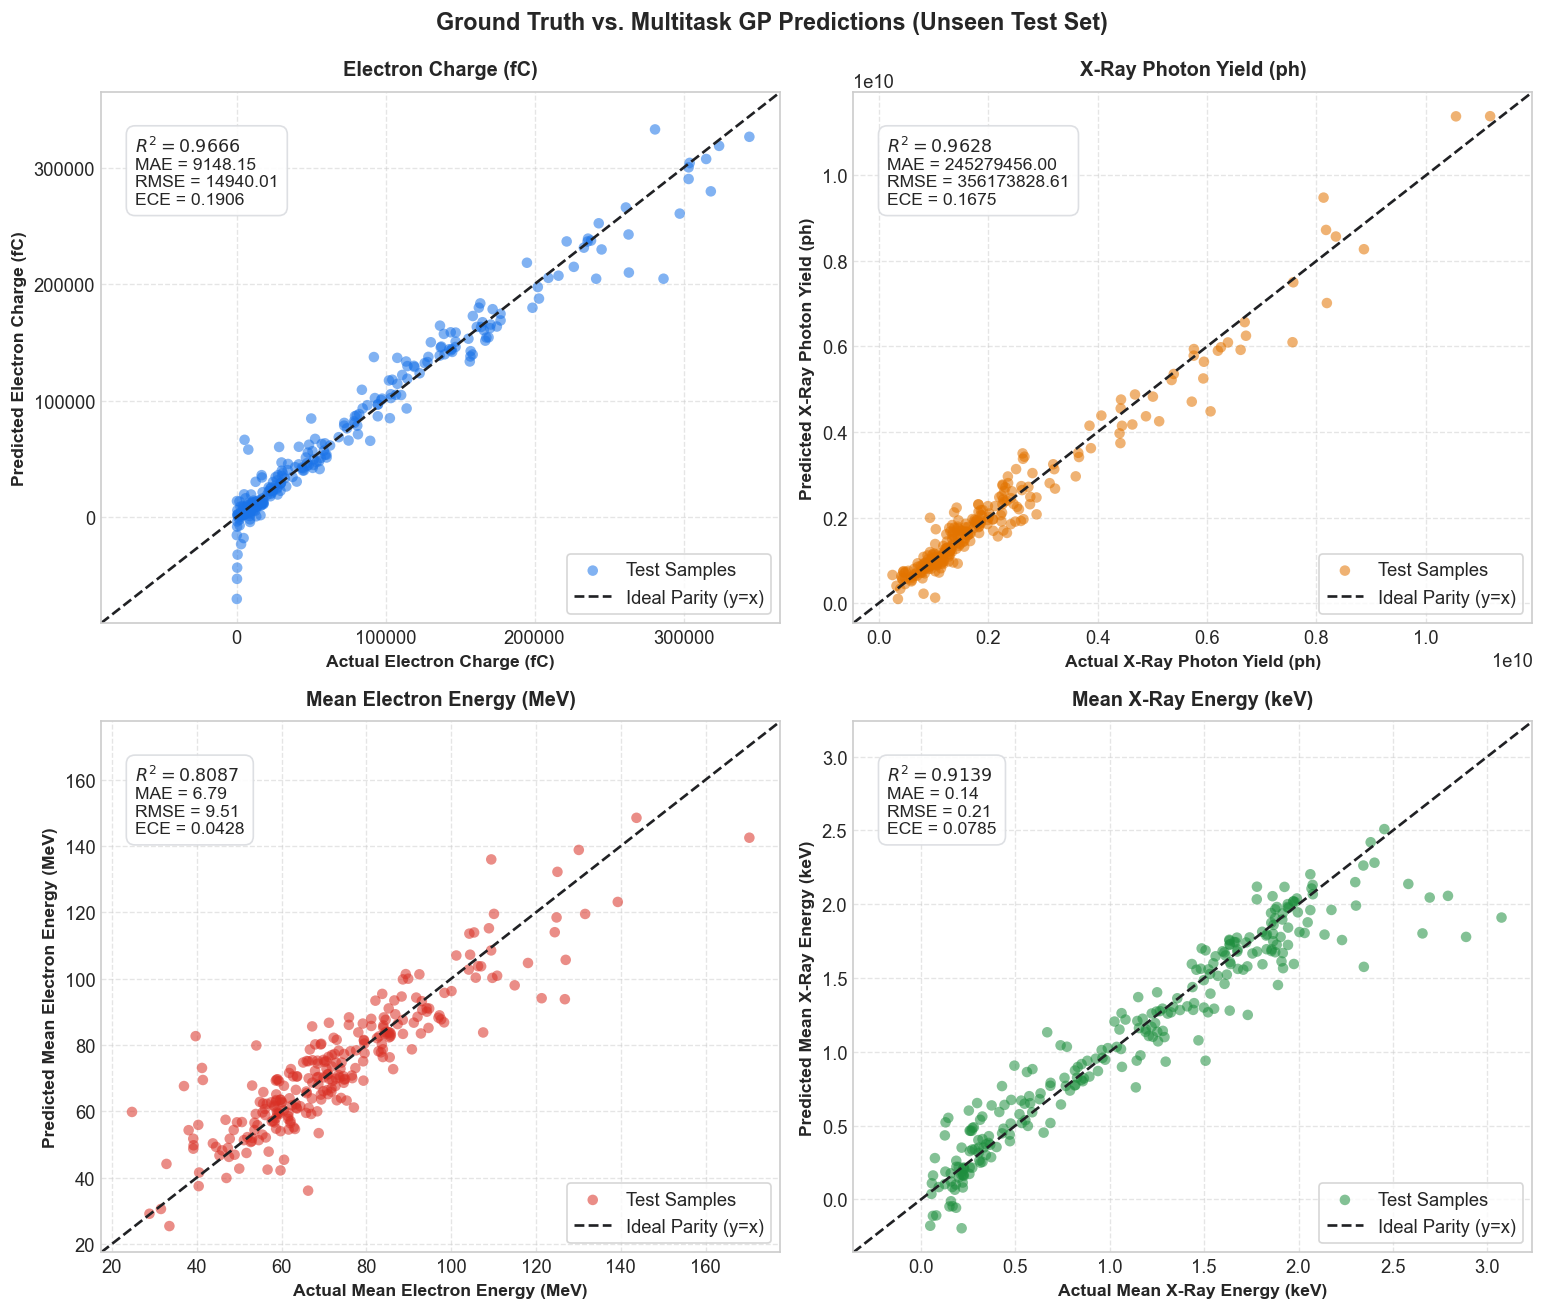

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11), dpi=120)
axes = axes.flatten()

plot_colors = ['#1a73e8', '#e37400', '#d93025', '#1e8e3e']

for idx, col in enumerate(target_cols):
    ax = axes[idx]
    y_true = y_test[:, idx]
    y_p = y_pred[:, idx]
    color = plot_colors[idx]
    
    r2 = metrics_data[idx]['R² Score']
    mae = metrics_data[idx]['MAE']
    rmse = metrics_data[idx]['RMSE']
    ece = metrics_data[idx]['Interval ECE']
    
    # Scatter test points
    ax.scatter(y_true, y_p, alpha=0.55, color=color, edgecolors='none', s=40, label='Test Samples')
    
    # Ideal parity line (y = x)
    min_val = min(y_true.min(), y_p.min())
    max_val = max(y_true.max(), y_p.max())
    margin = 0.05 * (max_val - min_val)
    line_min = min_val - margin
    line_max = max_val + margin
    ax.plot([line_min, line_max], [line_min, line_max], color='#202124', linestyle='--', linewidth=1.6, label='Ideal Parity (y=x)')
    ax.set_xlim(line_min, line_max)
    ax.set_ylim(line_min, line_max)
    
    # Metrics textbox
    metric_box = f"$R^2 = {r2:.4f}$\nMAE = {mae:.2f}\nRMSE = {rmse:.2f}\nECE = {ece:.4f}"
    ax.text(0.05, 0.92, metric_box, transform=ax.transAxes, fontsize=10.5,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#dadce0'))
    
    ax.set_title(target_names[col], fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel(f"Actual {target_names[col]}", fontsize=10.5, fontweight='bold')
    ax.set_ylabel(f"Predicted {target_names[col]}", fontsize=10.5, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', frameon=True)

plt.suptitle("Ground Truth vs. Multitask GP Predictions (Unseen Test Set)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()

# Save plot to notebooks/results/multitask_gp/
parity_plot_path = os.path.join(RESULTS_DIR, "parity_plots.png")
plt.savefig(parity_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved parity plots to: {parity_plot_path}")

plt.show()


## 7. Evaluation on Unseen 5th Set ()


In [5]:
# 1. Load the 5th set (test_selected_data.csv)
test_data_paths = [
    "data/test_selected_data.csv",
    "./data/test_selected_data.csv",
    "../../data/test_selected_data.csv",
    "../data/test_selected_data.csv"
]
test_file = next((p for p in test_data_paths if os.path.exists(p)), None)
if test_file is None:
    raise FileNotFoundError("Could not locate data/test_selected_data.csv")

df_set5 = pd.read_csv(test_file)
print(f"Loaded 5th set ({test_file}) with shape: {df_set5.shape}")

# 2. Extract inputs and ground truth targets
X_set5 = df_set5[input_cols].values
y_set5 = df_set5[target_cols].values

# 3. Standardize inputs using the fitted training scaler
X_set5_scaled = scaler_x.transform(X_set5)
test_x_set5 = torch.tensor(X_set5_scaled, dtype=torch.float32)
y_set5_scaled = scaler_y.transform(y_set5)

# 4. Predict with Multitask GP
model.eval()
likelihood.eval()

with torch.no_grad():
    preds_dist = likelihood(model(test_x_set5))
    mean_preds_scaled = preds_dist.mean.numpy()
    std_preds_scaled = np.sqrt(preds_dist.variance.numpy())

# Inverse-transform predictions back to true physical units
y_pred_set5 = scaler_y.inverse_transform(mean_preds_scaled)

# 5. Append predictions to the DataFrame
for idx, col in enumerate(target_cols):
    df_set5[f"pred_{col}"] = y_pred_set5[:, idx]

# Save augmented dataset with predictions
augmented_csv_path = os.path.join(RESULTS_DIR, "test_selected_data_with_predictions.csv")
df_set5.to_csv(augmented_csv_path, index=False)
print(f"Saved augmented dataset with predictions to: {augmented_csv_path}\n")

# 6. Compute evaluation metrics (MAE, RMSE, R2, ECE)
set5_metrics = []
for idx, col in enumerate(target_cols):
    y_true = y_set5[:, idx]
    y_p = y_pred_set5[:, idx]
    
    mae = mean_absolute_error(y_true, y_p)
    rmse = np.sqrt(mean_squared_error(y_true, y_p))
    r2 = r2_score(y_true, y_p)
    ece = regression_interval_ece(y_set5_scaled[:, idx], mean_preds_scaled[:, idx], std_preds_scaled[:, idx])
    
    set5_metrics.append({
        'Output Scalar': target_names[col],
        'MAE': mae,
        'RMSE': rmse,
        'R² Score': r2,
        'Interval ECE': ece
    })

set5_metrics_df = pd.DataFrame(set5_metrics)

# Save metrics summary to CSV
metrics_csv_path = os.path.join(RESULTS_DIR, "set5_metrics_summary.csv")
set5_metrics_df.to_csv(metrics_csv_path, index=False)
print(f"Saved 5th set metrics summary to: {metrics_csv_path}\n")

print("=" * 95)
print("             5th SET EVALUATION PERFORMANCE (PHYSICAL UNITS)                    ")
print("=" * 95)
print(set5_metrics_df.to_string(index=False, justify='center', float_format=lambda x: f"{x:14.4f}"))
print("=" * 95)
print(f"Mean R² Score across all 4 scalars on 5th set: {set5_metrics_df['R² Score'].mean():.4f}")
print(f"Mean Interval ECE across all 4 scalars on 5th set: {set5_metrics_df['Interval ECE'].mean():.4f}")


Loaded 5th set (data/test_selected_data.csv) with shape: (594, 9)


Saved augmented dataset with predictions to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results/test_selected_data_with_predictions.csv

Saved 5th set metrics summary to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results/set5_metrics_summary.csv

             5th SET EVALUATION PERFORMANCE (PHYSICAL UNITS)                    
      Output Scalar              MAE           RMSE         R² Score     Interval ECE 
      Electron Charge (fC)     13037.2204     23581.3090         0.9334         0.1696
   X-Ray Photon Yield (ph) 260067803.9854 379918321.1896         0.9630         0.1848
Mean Electron Energy (MeV)         7.1362         9.9079         0.8074         0.0890
   Mean X-Ray Energy (keV)         0.1546         0.2261         0.8975         0.0813
Mean R² Score across all 4 scalars on 5th set: 0.9003
Mean Interval ECE across all 4 scalars on 5th set: 0.1312


## 8. Ground Truth vs. Predicted Parity Plots (5th Set)


Saved 5th set parity plots to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results/set5_parity_plots.png


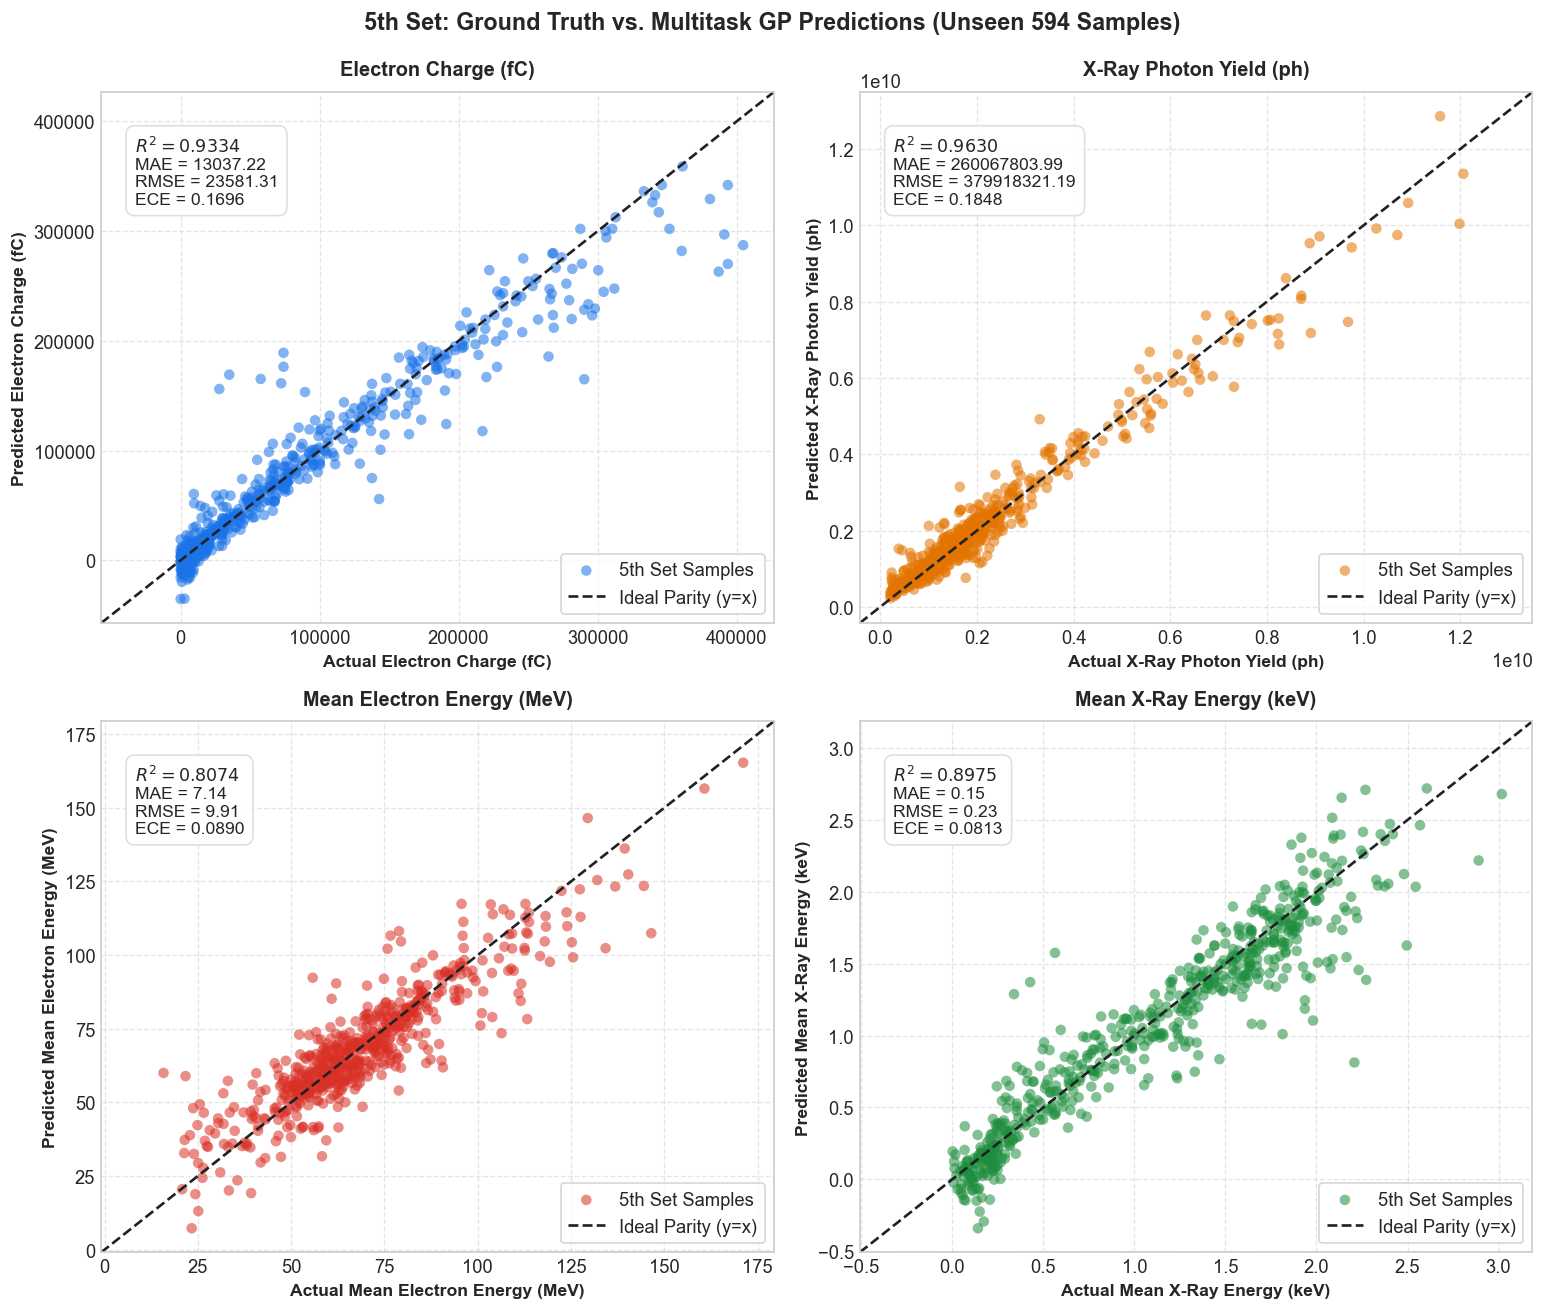

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11), dpi=120)
axes = axes.flatten()

plot_colors = ['#1a73e8', '#e37400', '#d93025', '#1e8e3e']

for idx, col in enumerate(target_cols):
    ax = axes[idx]
    y_true = y_set5[:, idx]
    y_p = y_pred_set5[:, idx]
    color = plot_colors[idx]
    
    r2 = set5_metrics[idx]['R² Score']
    mae = set5_metrics[idx]['MAE']
    rmse = set5_metrics[idx]['RMSE']
    ece = set5_metrics[idx]['Interval ECE']
    
    # Scatter 5th set points
    ax.scatter(y_true, y_p, alpha=0.55, color=color, edgecolors='none', s=40, label='5th Set Samples')
    
    # Ideal parity line (y = x)
    min_val = min(y_true.min(), y_p.min())
    max_val = max(y_true.max(), y_p.max())
    margin = 0.05 * (max_val - min_val)
    line_min = min_val - margin
    line_max = max_val + margin
    ax.plot([line_min, line_max], [line_min, line_max], color='#202124', linestyle='--', linewidth=1.6, label='Ideal Parity (y=x)')
    ax.set_xlim(line_min, line_max)
    ax.set_ylim(line_min, line_max)
    
    # Metrics textbox
    metric_box = f"$R^2 = {r2:.4f}$\nMAE = {mae:.2f}\nRMSE = {rmse:.2f}\nECE = {ece:.4f}"
    ax.text(0.05, 0.92, metric_box, transform=ax.transAxes, fontsize=10.5,
            verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='#dadce0'))
    
    ax.set_title(target_names[col], fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel(f"Actual {target_names[col]}", fontsize=10.5, fontweight='bold')
    ax.set_ylabel(f"Predicted {target_names[col]}", fontsize=10.5, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='lower right', frameon=True)

plt.suptitle("5th Set: Ground Truth vs. Multitask GP Predictions (Unseen 594 Samples)", fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()

# Save parity plot
parity_plot_path = os.path.join(RESULTS_DIR, "set5_parity_plots.png")
plt.savefig(parity_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved 5th set parity plots to: {parity_plot_path}")

plt.show()
